# Laboratorio: backtest del Portafolio J
**Autor:** Andrés Alejandro Rodríguez Lozano · Octubre 2026

> ⚠️ **Material educativo, no es recomendación de inversión.** Esto es un **laboratorio**, no un candidato a mezcla: varios tickers (VT, SCHD, BLK, ITA, MCHI, REMX, COHR) están por fuera de la tesis del core (SPYG, SMH, BRK.B, IEMG, VTI).

**Pregunta:** si alguien hubiera invertido US\$1.000 al inicio y US\$200 cada mes en este portafolio, ¿cuánto tendría hoy a 10 y a 15 años? ¿Cómo le fue frente al S&P 500 (SPY) y frente al core de Alejandro con exactamente el mismo flujo de dinero?

**Capítulos**
1. Preparar el entorno
2. Los pesos (captura eToro 18-oct-2026)
3. Descargar precios (Yahoo Adjusted Close) con caché
4. Historia incompleta: método sensibilidad
5. Cómo funciona el motor (aportes, rebalanceo, costos)
6. Validaciones antes de mirar resultados
7. Resultados 10 y 15 años
8. Subperiodos 2020 y 2022
9. ¿Qué activo aportó la ganancia?
10. Sensibilidad a costos 0 / 5 / 15 bps
11. Conclusiones y limitaciones

## 1. Preparar el entorno
Todo el código vive en `src/` para que el notebook se lea como una clase: aquí solo llamamos funciones y explicamos.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np
from IPython.display import Image, display
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 20)
from src import config as C
from src.data import get_prices, first_valid_dates
from src.backtest import build_returns, run, contribution_dates
from src import validate as V
from src.pipeline import run_all, cost_sensitivity, OUT

## 2. Los pesos
Tomamos el **% por valor** (columna *Valor*) de la captura del 18-oct-2026. Suman 100,01% por redondeo, así que se normalizan a 100%. En Yahoo, BRK.B se escribe `BRK-B`.

In [2]:
w = pd.DataFrame({'Peso captura %': C.PORT_J_RAW, 'Peso normalizado': C.PORTFOLIOS['Portafolio J (laboratorio)']})
print('Suma captura:', round(sum(C.PORT_J_RAW.values()), 2))
w.style.format({'Peso captura %': '{:.2f}', 'Peso normalizado': '{:.4%}'})

Suma captura: 100.01


,Peso captura %,Peso normalizado
VT,20.81,20.8079%
SPYG,20.82,20.8179%
SCHD,15.01,15.0085%
BLK,12.81,12.8087%
ITA,12.00,11.9988%
SMH,9.55,9.5490%
MCHI,3.04,3.0397%
REMX,3.44,3.4397%
COHR,2.53,2.5297%


In [3]:
pd.Series(C.PORTFOLIOS['Core Alejandro'], name='Core Alejandro (benchmark)').map('{:.2%}'.format)

SPYG     30.51%
SMH      21.76%
BRK-B    20.40%
IEMG     20.15%
VTI       7.18%
Name: Core Alejandro (benchmark), dtype: str

## 3. Descargar precios
Usamos **Adjusted Close** de Yahoo (ajusta dividendos y splits ⇒ retorno total aproximado). La primera vez se descarga con `yfinance` y se guarda en `data/precios.parquet`; las siguientes se lee la caché.

In [4]:
px = get_prices(C.ALL_TICKERS)
print(px.shape, '|', px.index.min().date(), '→', px.index.max().date())
first_valid_dates(px).rename('Primer dato').to_frame()

(3971, 13) | 2011-01-03 → 2026-10-16


,Primer dato
Ticker,
BLK,2011-01-03
BRK-B,2011-01-03
COHR,2011-01-03
IEMG,2012-10-24
ITA,2011-01-03
MCHI,2011-03-31
REMX,2011-01-03
SCHD,2011-10-20
SMH,2011-01-03


## 4. Historia incompleta: método sensibilidad
- **SCHD** tiene su primer precio el **20-oct-2011**, pero la ventana de 15 años arranca con el aporte del **3-oct-2011**. Faltan 14 sesiones.
- **IEMG** (benchmark core) arranca el **24-oct-2012**: falta ~1 año de la ventana de 15 años.

Regla: **no inventamos series**. Antes del lanzamiento usamos el retorno diario real de SPY (S&P 500 total return), y desde el primer día con precio usamos el ETF real. En la ventana de 10 años todo es dato real.

In [5]:
for h, start in C.HORIZONS.items():
    for name in ['Portafolio J (laboratorio)', 'Core Alejandro']:
        r, m = build_returns(px, list(C.PORTFOLIOS[name]), start, C.END, C.PROXY)
        s = m.sum(); s = s[s > 0]
        print(f'{h} · {name}:', dict(s) if len(s) else 'todo dato real')

10 años · Portafolio J (laboratorio): todo dato real
10 años · Core Alejandro: todo dato real
15 años · Portafolio J (laboratorio): {'SCHD': np.int64(14)}
15 años · Core Alejandro: {'IEMG': np.int64(269)}


## 5. El motor del backtest
Reglas (en `src/backtest.py`):
1. **Aportes:** US\$1.000 el primer día hábil de oct-2016 (10 a) u oct-2011 (15 a); luego US\$200 el primer día hábil de cada mes siguiente, hasta oct-2026 inclusive ⇒ 120 y 180 aportes mensuales.
2. **Rebalanceo mensual** al cierre del día del aporte: el dinero nuevo y lo que se haya desviado vuelven a los pesos objetivo.
3. **Costos:** 5 bps sobre el nocional negociado (compras + ventas), supuesto conservador que también cobra la compra del aporte.
4. **Sin look-ahead:** el retorno del día *t* se aplica a las tenencias del cierre *t-1*.
5. Valoración final al último cierre disponible: **16-oct-2026**.

**Dos rentabilidades distintas:**
- **TWR (CAGR)** mide la estrategia, sin importar cuándo entró la plata.
- **XIRR (money-weighted)** mide la experiencia del inversionista con sus fechas de aporte.

In [6]:
idx = px.loc['2016-10-01':C.END].index
cd = contribution_dates(idx)
print('Primeros días de aporte:', [d.date() for d in cd[:4]], '... último:', cd[-1].date(), '| total fechas:', len(cd))

Primeros días de aporte: [datetime.date(2016, 10, 3), datetime.date(2016, 11, 1), datetime.date(2016, 12, 1), datetime.date(2017, 1, 3)] ... último: 2026-10-01 | total fechas: 121


## 6. Validaciones (asserts)
`run_all()` corre **todas** las validaciones antes de calcular métricas; si alguna falla, se detiene con error. Aquí las vemos explícitamente.

In [7]:
all_res, tables, contribs, log = run_all()
for v in log['validaciones']: print('✔', v)

✔ 10 años · Core Alejandro: panel sin NaN (2524 sesiones × 5), pesos suman 1, mensual en [-17.6%, 32.2%], 120 aportes mensuales + inicial, aportado=25,000=1000+200×120, sin look-ahead (corte 2021-10-07), contabilidad cuadra
✔ 10 años · Portafolio J (laboratorio): panel sin NaN (2524 sesiones × 9), pesos suman 1, mensual en [-33.4%, 48.8%], 120 aportes mensuales + inicial, aportado=25,000=1000+200×120, sin look-ahead (corte 2021-10-07), contabilidad cuadra
✔ 10 años · SPY: panel sin NaN (2524 sesiones × 1), pesos suman 1, mensual en [-12.5%, 12.7%], 120 aportes mensuales + inicial, aportado=25,000=1000+200×120, sin look-ahead (corte 2021-10-07), contabilidad cuadra
✔ 15 años · Core Alejandro: panel sin NaN (3782 sesiones × 5), pesos suman 1, mensual en [-17.6%, 32.2%], 180 aportes mensuales + inicial, aportado=37,000=1000+200×180, sin look-ahead (corte 2019-04-10), contabilidad cuadra
✔ 15 años · Portafolio J (laboratorio): panel sin NaN (3782 sesiones × 9), pesos suman 1, mensual en [-

Qué se validó:
- Panel de retornos **sin NaN** ni infinitos, retornos diarios < 50% en valor absoluto.
- Retornos **mensuales** de cada activo entre −60% y +100%.
- **Pesos suman 1** y no son negativos.
- **Conteo de meses**: 120 (10 a) y 180 (15 a) aportes mensuales + inicial; **aportado = 1.000 + 200·n**.
- **Sin look-ahead**: se alteran los retornos después de una fecha de corte y el camino previo debe quedar idéntico.
- **Contabilidad**: valor final = aportes + P&L de activos − costos.

## 7. Resultados

In [8]:
def fmt(t):
    t = t.copy().astype(object)
    usd = ['Capital aportado','Valor final','Ganancia','Costos acumulados']
    pct = ['CAGR (TWR)','XIRR (MWR)','Volatilidad','Max DD','% tiempo bajo agua','Turnover anual (una vía)','Tracking error vs core','2020 retorno','2020 max DD','2022 retorno','2022 max DD']
    num = ['Sharpe rf=0','Sharpe rf=4%','Sortino rf=0','Sortino rf=4%','Calmar','Ulcer']
    for r in t.index:
        for c in t.columns:
            v = t.loc[r, c]
            if isinstance(v, str): continue
            if pd.isna(v): t.loc[r, c] = '—'
            elif r in usd: t.loc[r, c] = f'US${v:,.0f}'
            elif r in pct: t.loc[r, c] = f'{v:.2%}'
            elif r in num: t.loc[r, c] = f'{v:.2f}'
            else: t.loc[r, c] = f'{v:,.0f}'
    return t
display(fmt(tables['10 años']))

,Portafolio J (laboratorio),Core Alejandro,SPY
Capital aportado,"US$25,000","US$25,000","US$25,000"
Valor final,"US$63,446","US$72,074","US$58,158"
Ganancia,"US$38,446","US$47,074","US$33,158"
CAGR (TWR),16.70%,18.56%,15.19%
XIRR (MWR),17.13%,19.40%,15.57%
Volatilidad,17.06%,16.67%,15.27%
Sharpe rf=0,0.99,1.11,1.00
Sharpe rf=4%,0.76,0.87,0.75
Sortino rf=0,1.62,1.85,1.63
Sortino rf=4%,1.19,1.38,1.15


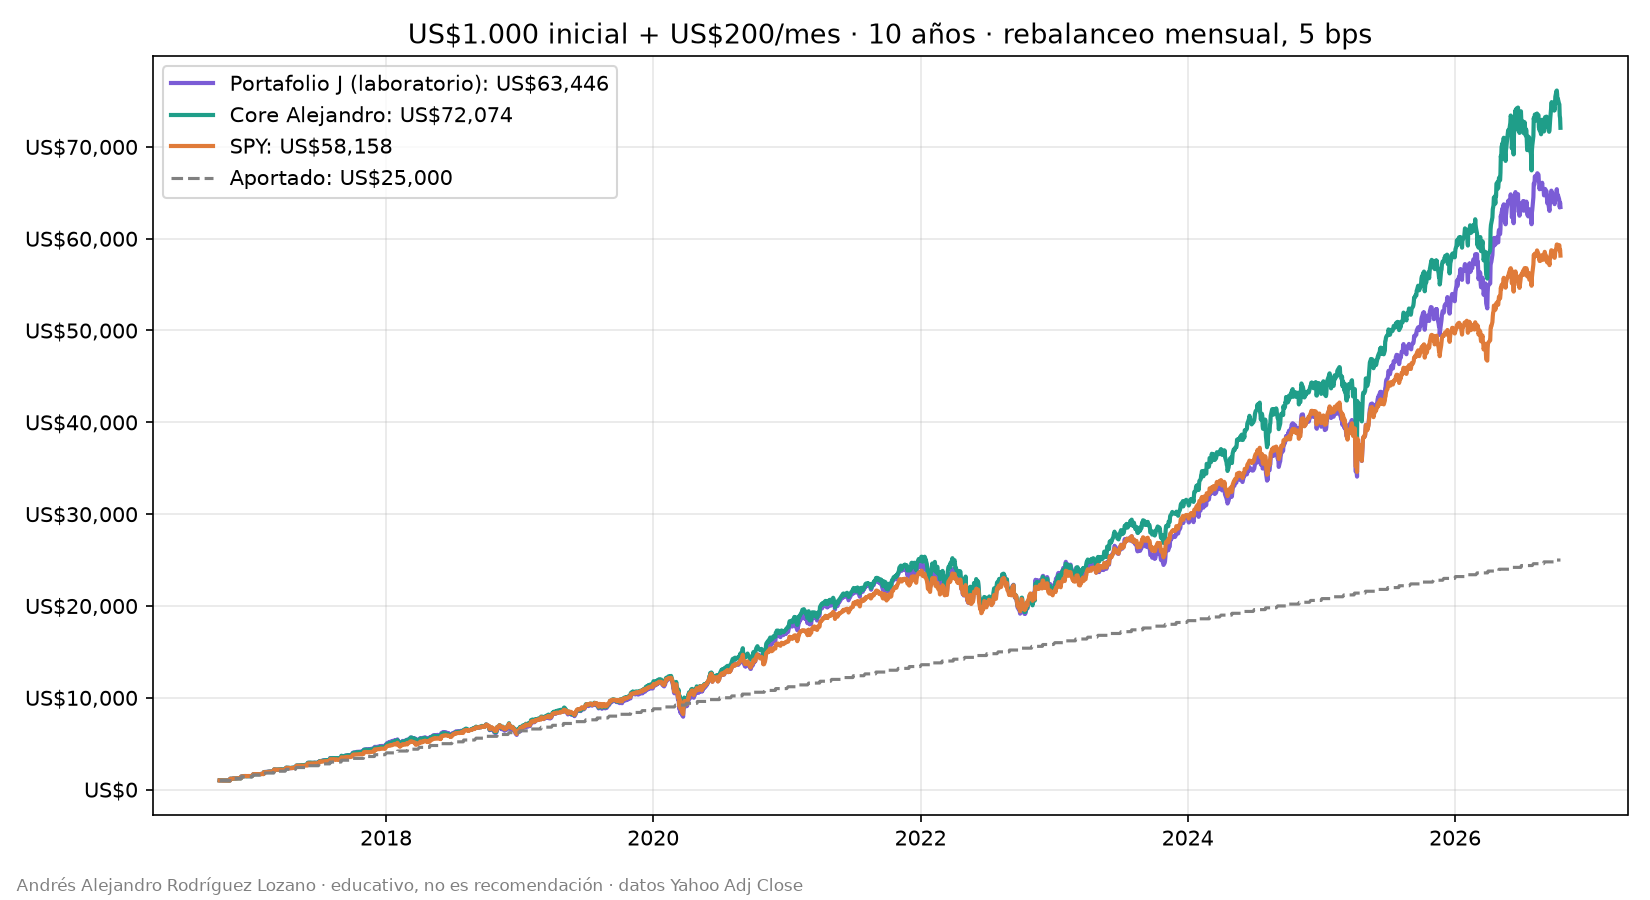

In [9]:
display(Image(str(OUT / 'curva_valor_10a.png')))

In [10]:
display(fmt(tables['15 años']))

,Portafolio J (laboratorio),Core Alejandro,SPY
Capital aportado,"US$37,000","US$37,000","US$37,000"
Valor final,"US$143,687","US$166,294","US$128,649"
Ganancia,"US$106,687","US$129,294","US$91,649"
CAGR (TWR),16.52%,17.61%,15.73%
XIRR (MWR),16.06%,17.68%,14.82%
Volatilidad,15.76%,15.30%,14.18%
Sharpe rf=0,1.05,1.14,1.10
Sharpe rf=4%,0.80,0.88,0.83
Sortino rf=0,1.78,1.96,1.88
Sortino rf=4%,1.29,1.44,1.33


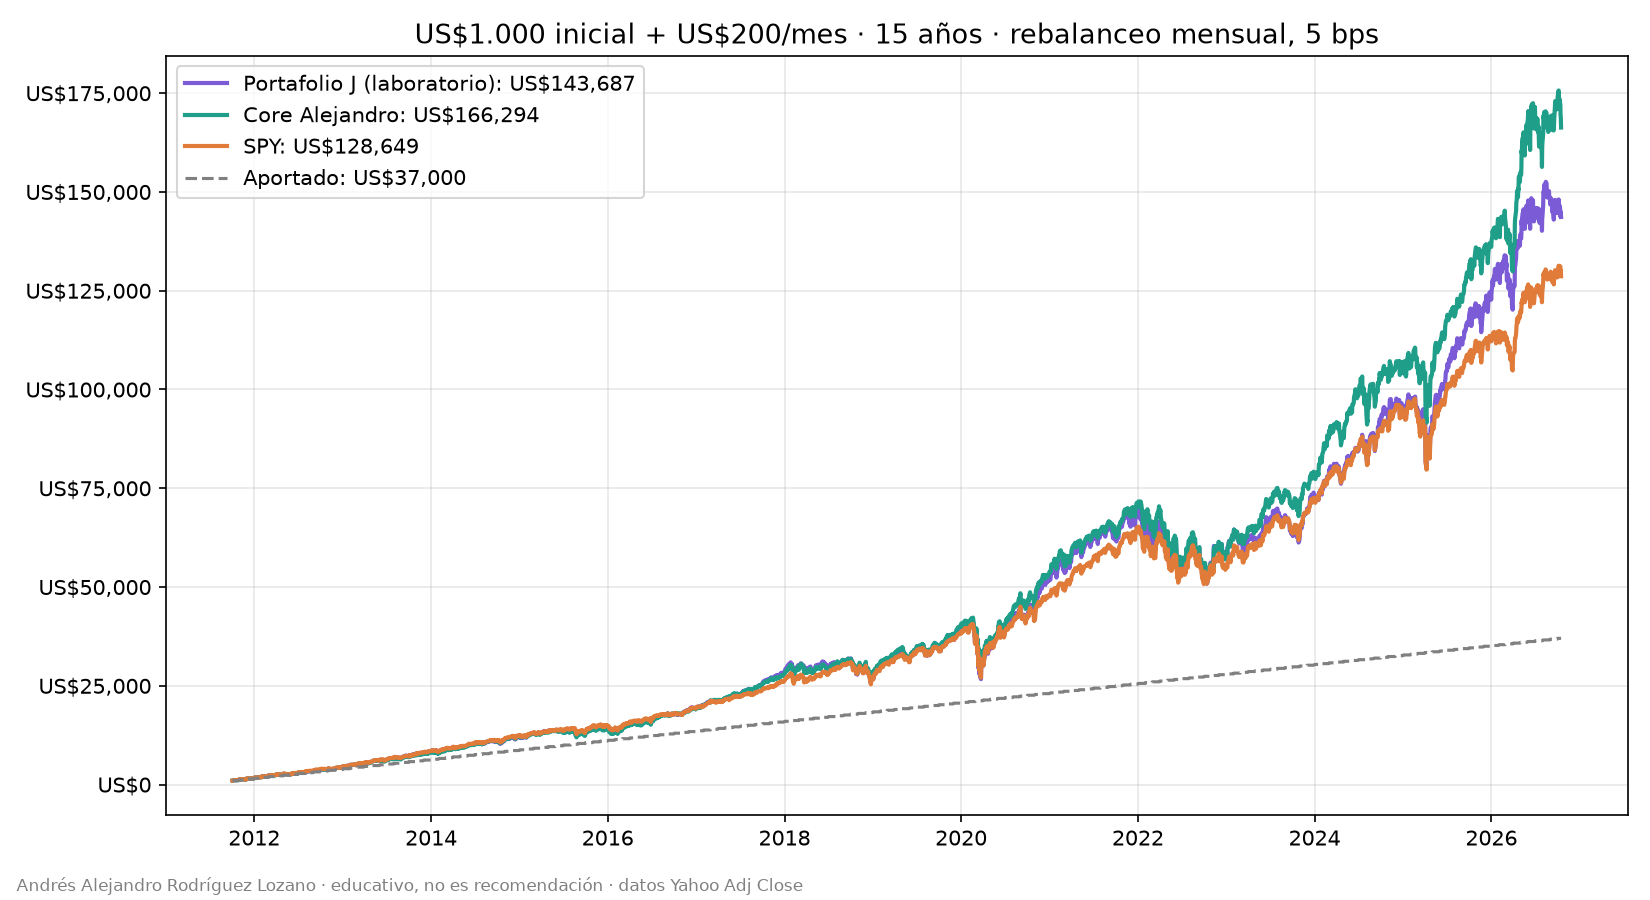

In [11]:
display(Image(str(OUT / 'curva_valor_15a.png')))

**Cómo leerlo**
- El **core** de Alejandro termina por encima en ambos horizontes, con menor drawdown y mejor Sharpe/Calmar que el de Portafolio J.
- El Portafolio J le gana a SPY en valor final, pero con **más volatilidad, más drawdown y mayor Ulcer**: paga más riesgo por ese extra.
- **% tiempo bajo agua** cuenta sesiones por debajo del máximo previo del índice TWR; en mercados alcistas casi todos los días están un poco por debajo del pico anterior, por eso es alto en los tres.

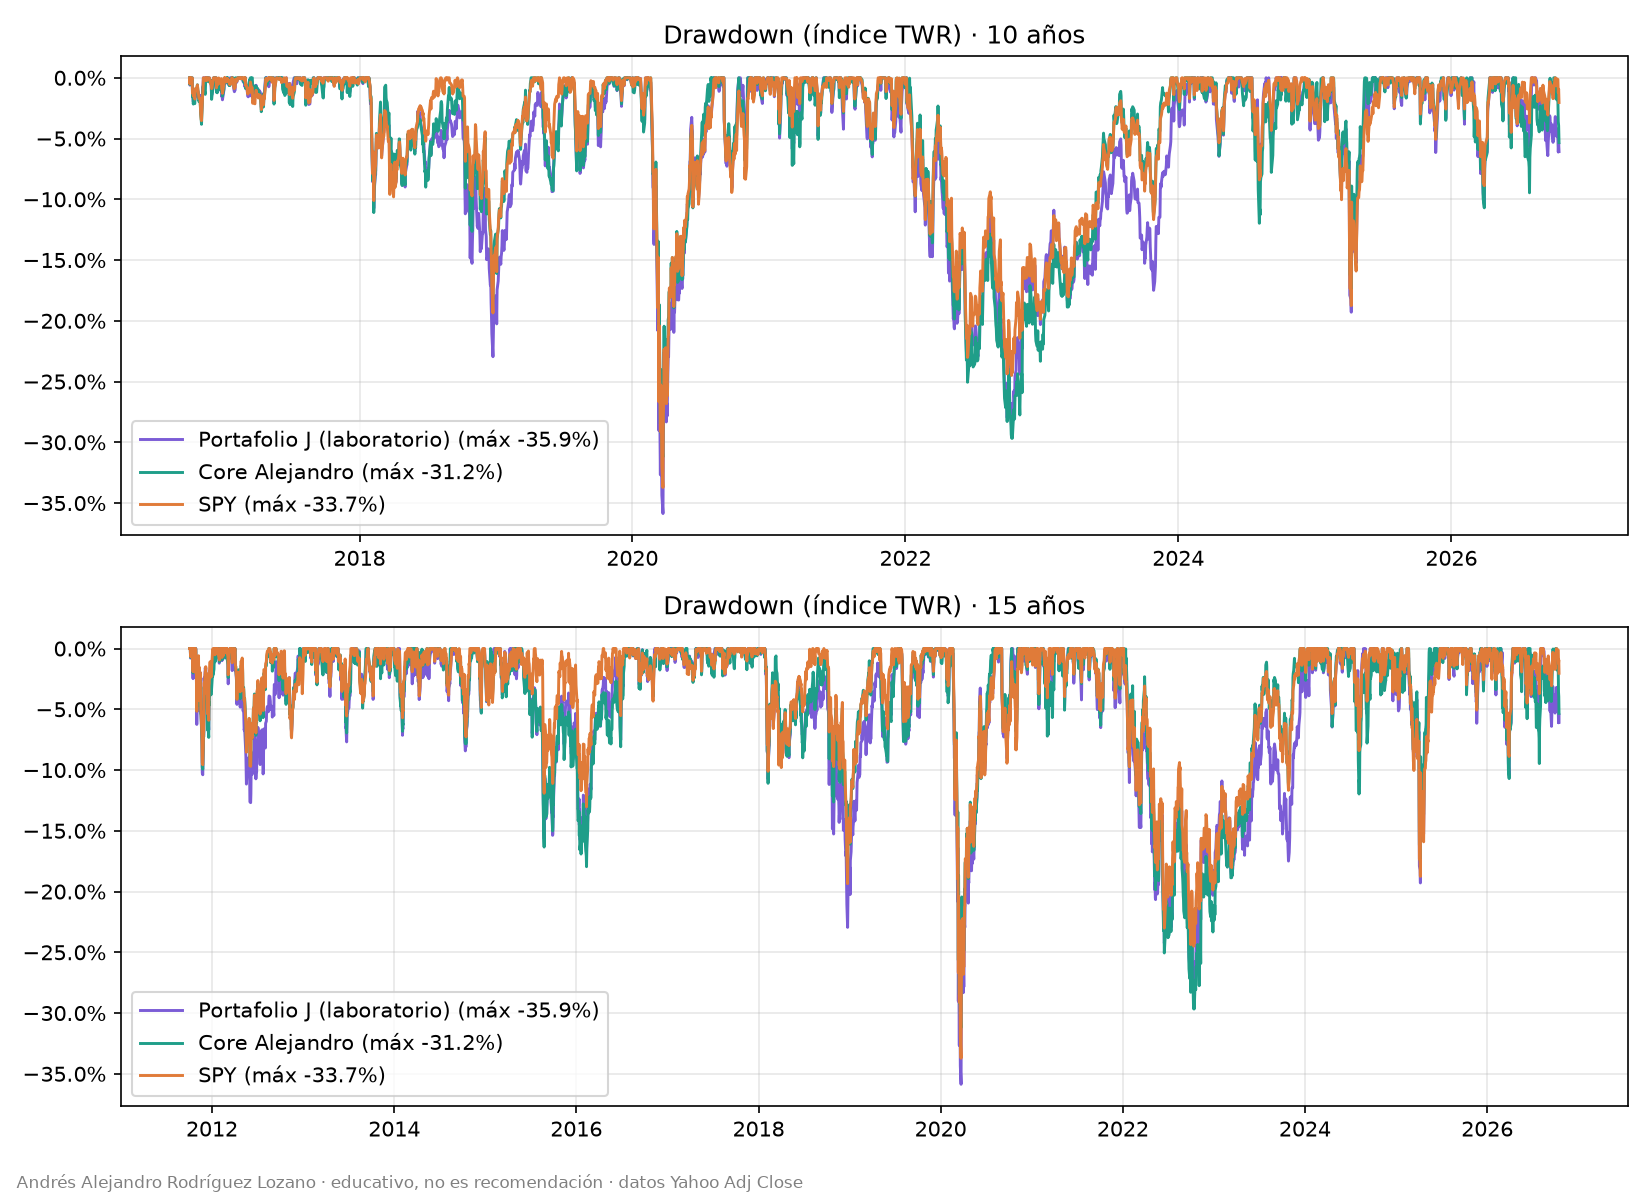

In [12]:
display(Image(str(OUT / 'drawdown.png')))

## 8. Subperiodos 2020 (COVID) y 2022 (subida de tasas)
Retorno TWR del año calendario y la peor caída dentro del año.

In [13]:
rows = []
for h in tables:
    for y in ['2020', '2022']:
        for n in tables[h].columns:
            rows.append({'Horizonte': h, 'Año': y, 'Portafolio': n, 'Retorno': tables[h].loc[f'{y} retorno', n], 'Max DD': tables[h].loc[f'{y} max DD', n]})
sub = pd.DataFrame(rows).query("Horizonte == '10 años'").drop(columns='Horizonte')
sub.style.format({'Retorno': '{:.2%}', 'Max DD': '{:.2%}'})

,Año,Portafolio,Retorno,Max DD
0,2020,Portafolio J (laboratorio),27.63%,-35.86%
1,2020,Core Alejandro,27.17%,-31.21%
2,2020,SPY,18.32%,-33.72%
3,2022,Portafolio J (laboratorio),-18.11%,-28.79%
4,2022,Core Alejandro,-21.26%,-29.66%
5,2022,SPY,-18.18%,-24.50%


## 9. Contribución de cada activo
P&L en dólares acumulado por activo (tenencia del día anterior × retorno del día), más la línea de costos. La suma es exactamente la ganancia total.

In [14]:
for h, c in contribs.items():
    print(h); display(c.style.format({'P&L USD': 'US${:,.0f}', '% de la ganancia': '{:.1%}'}))

10 años


,P&L USD,% de la ganancia
VT,"US$6,132",16.0%
SPYG,"US$8,268",21.5%
SCHD,"US$4,799",12.5%
BLK,"US$4,166",10.8%
ITA,"US$3,871",10.1%
SMH,"US$8,030",20.9%
MCHI,US$85,0.2%
REMX,US$554,1.4%
COHR,"US$2,587",6.7%
Costos,US$-47,-0.1%


15 años


,P&L USD,% de la ganancia
VT,"US$16,692",15.6%
SPYG,"US$23,145",21.7%
SCHD,"US$13,448",12.6%
BLK,"US$12,218",11.5%
ITA,"US$11,222",10.5%
SMH,"US$21,619",20.3%
MCHI,US$418,0.4%
REMX,"US$1,394",1.3%
COHR,"US$6,654",6.2%
Costos,US$-121,-0.1%


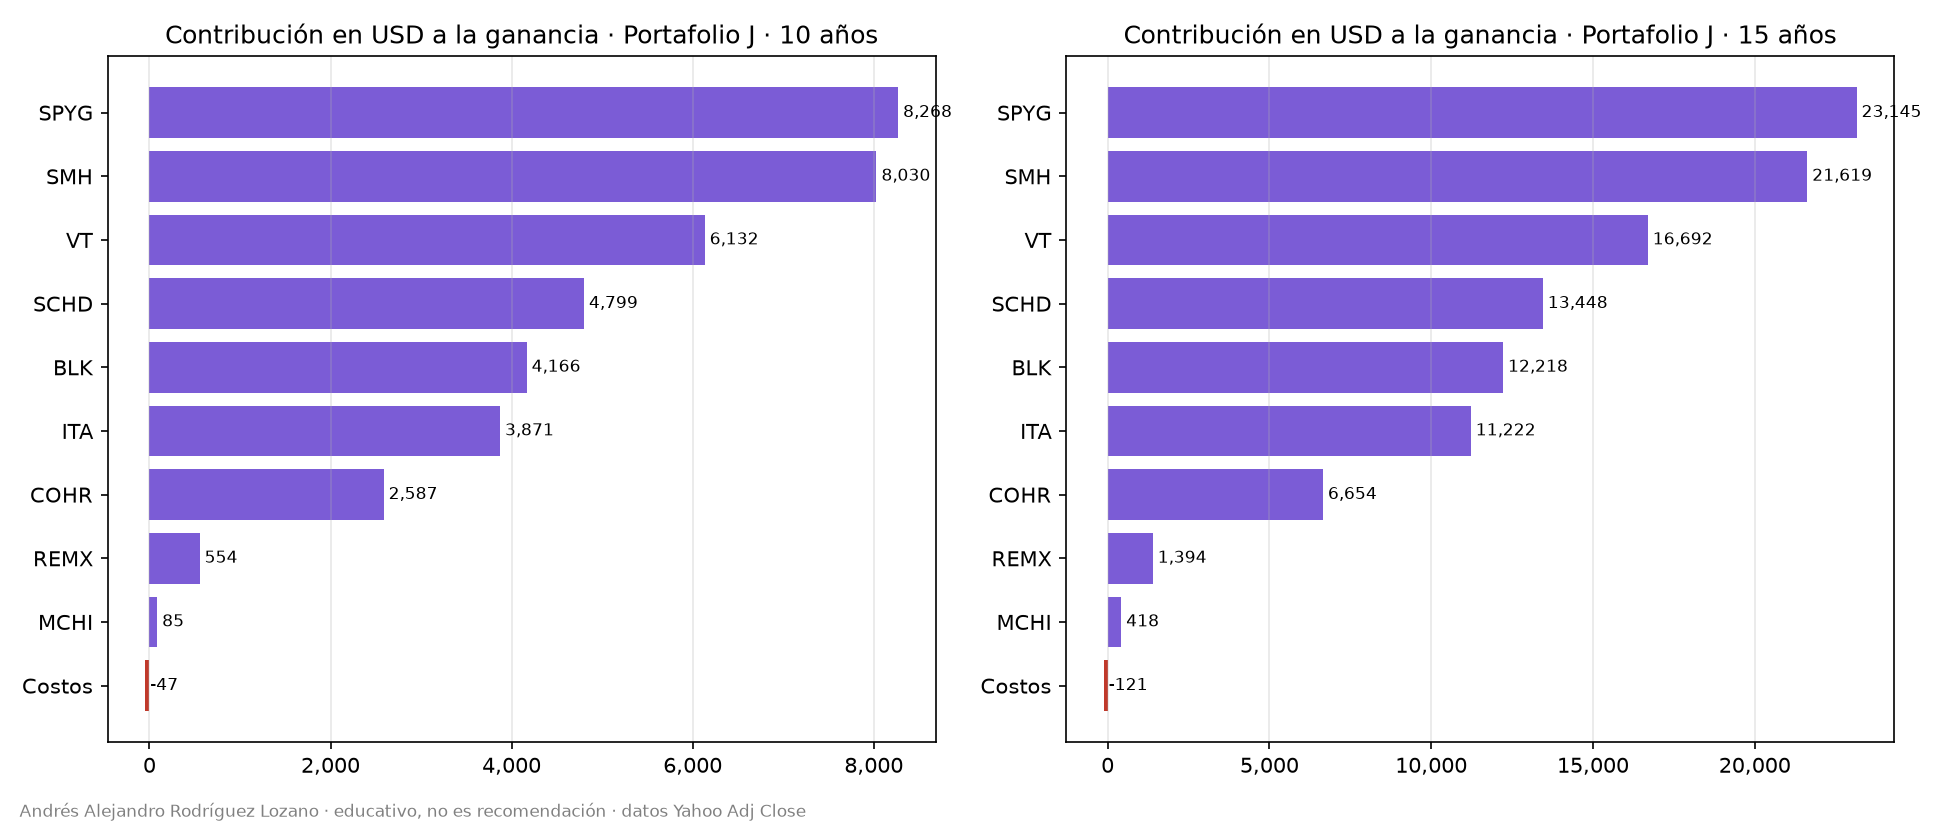

In [15]:
display(Image(str(OUT / 'contribucion_activos.png')))

## 10. Sensibilidad a costos (0 / 5 / 15 bps)

In [16]:
cs = cost_sensitivity()
cs.pivot_table(index=['Horizonte','Portafolio'], columns='bps', values=['Valor final','XIRR']).style.format('{:,.4f}')

Con rebalanceo mensual y turnover de ~15% anual, pasar de 0 a 15 bps cuesta del orden de US\$250–500 en 15 años: **los costos no cambian el ranking**.

## 11. Conclusiones y limitaciones
**Hallazgos**
1. Con el mismo flujo (US\$1.000 + US\$200/mes), el ranking es **Core > Portafolio J > SPY** en 10 y 15 años.
2. Portafolio J supera a SPY por la exposición a **SPYG, SMH y COHR**, mientras **MCHI y REMX** casi no aportan (≈1,7% de la ganancia entre los dos), y tiene el peor drawdown (COVID, −35,9%) de los tres. Ajustado por riesgo (Sharpe, Calmar) queda **parejo o por debajo de SPY**.
3. Su tracking error vs el core es de ~5% anual: se parecen bastante (comparten SPYG y SMH), y la diferencia la explican sobre todo el menor peso en SMH y la ausencia de BRK.B/IEMG frente a los satélites (BLK, ITA, COHR, MCHI, REMX).
4. En 2022 el de Portafolio J cayó lo mismo que SPY (≈ −18%) y menos que el core (−21%), gracias a SCHD, ITA y BLK.

**Limitaciones**
- Pesos **actuales** aplicados hacia atrás ⇒ sesgo de retrospectiva (hoy se ven bien SMH y COHR porque subieron).
- Adjusted Close de Yahoo ≈ retorno total; no incluye impuestos, spreads de eToro, conversión COP/USD ni retención de dividendos.
- Método sensibilidad: 14 sesiones de SCHD (oct-2011) y ~1 año de IEMG en el core se aproximan con SPY.
- COHR en Yahoo es la serie continua de II-VI (renombrada en 2022).
- El pasado no garantiza el futuro.

*Andrés Alejandro Rodríguez Lozano · laboratorio educativo · octubre 2026*